In [8]:
import numpy as np
import scipy.special
import matplotlib.pyplot as plt

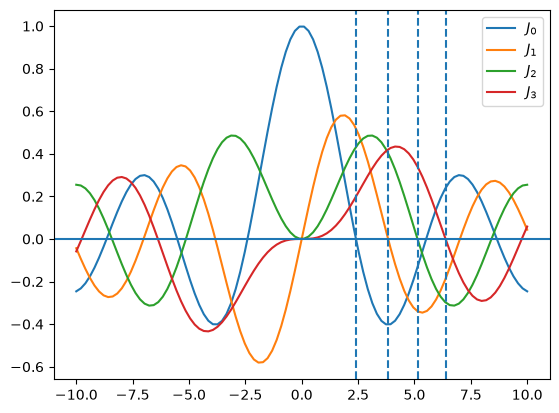

In [28]:
x = np.linspace(-10,10,100)
j0 = scipy.special.jn(0,x)
j1 = scipy.special.jn(1,x)
j2 = scipy.special.jn(2,x)
j3 = scipy.special.jn(3,x)
x01 = scipy.special.jn_zeros(0, 1)[0]
x11 = scipy.special.jn_zeros(1, 1)[0]
x21 = scipy.special.jn_zeros(2, 1)[0]
x31 = scipy.special.jn_zeros(3, 1)[0]
plt.plot(x,j0, label="$J_0$")
plt.plot(x,j1, label="$J_1$")
plt.plot(x,j2, label="$J_2$")
plt.plot(x,j3, label="$J_3$")
plt.axvline(x01, ls="--")
plt.axvline(x11, ls="--")
plt.axvline(x21, ls="--")
plt.axvline(x31, ls="--")
plt.axhline(0)
plt.legend()


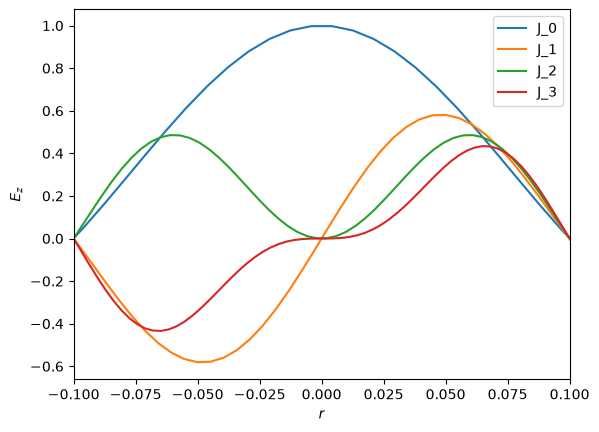

In [40]:
R = 0.1
plt.plot(x/x01*R, j0, label="J_0")
plt.plot(x/x11*R, j1, label="J_1")
plt.plot(x/x21*R, j2, label="J_2")
plt.plot(x/x31*R, j3, label="J_3")
plt.xlim(-R,R)
plt.ylabel("$E_z$")
plt.xlabel("$r$")
plt.legend()

(<Axes: title={'center': '$TM_{010}$  $E_z$  ($\\phi_0$ = 0°),  f = 0.115 GHz'}, xlabel='z (m)', ylabel='x (m)'>,
 np.float64(114742527.83521006))

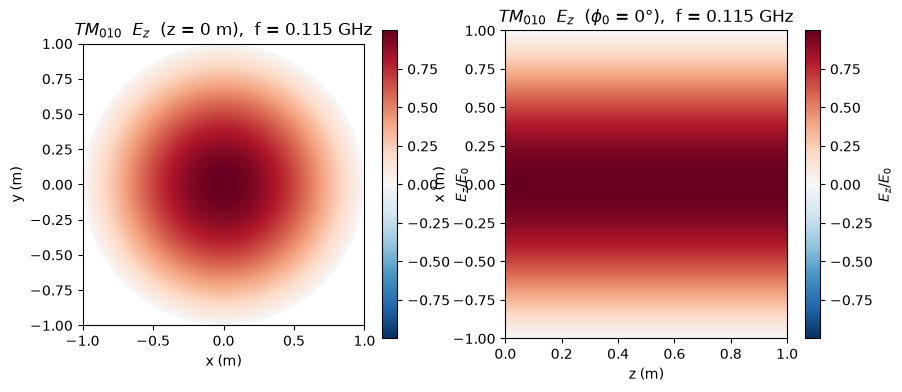

In [60]:
C = 299792458.0  # speed of light, m/s
 
def plot_Ez_pillbox(m=0, n=1, p=0, R=1.0, L=1.0, plane="xy",
                    z0=0.0, phi0=0.0, N=400, cmap="RdBu_r", ax=None):

    x_mn = scipy.special.jn_zeros(m, n)[-1]                         # n-th zero of J_m
    f = (C / (2 * np.pi)) * np.hypot(x_mn / R, p * np.pi / L)
 
    if plane == "xy":
        x = np.linspace(-R, R, N)
        y = np.linspace(-R, R, N)
        X, Y = np.meshgrid(x, y)
        r, phi = np.hypot(X, Y), np.arctan2(Y, X)
        Ez = scipy.special.jv(m, x_mn * r / R) * np.cos(m * phi) * np.cos(p * np.pi * z0 / L)
        Ez = np.where(r <= R, Ez, np.nan)             # mask outside the wall
        extent = [-R, R, -R, R]
        xlabel, ylabel = "x (m)", "y (m)"
        title_extra = f"z = {z0:g} m"
    elif plane == "rz":
        z = np.linspace(0, L, N)
        xs = np.linspace(-R, R, N)
        Z, XS = np.meshgrid(z, xs)
        r = np.abs(XS)
        phi = np.where(XS >= 0, phi0, phi0 + np.pi)
        Ez = scipy.special.jv(m, x_mn * r / R) * np.cos(m * phi) * np.cos(p * np.pi * Z / L)
        extent = [0, L, -R, R]
        xlabel, ylabel = "z (m)", "x (m)"
        title_extra = f"$\\phi_0$ = {np.degrees(phi0):g}°"
    else:
        raise ValueError("plane must be 'xy' or 'rz'")
 
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
 
    vmax = np.nanmax(np.abs(Ez)) or 1.0               # symmetric colour scale
    im = ax.imshow(Ez, origin="lower", extent=extent, cmap=cmap,
                   vmin=-vmax, vmax=vmax, aspect="equal" if plane == "xy" else "auto")
    ax.figure.colorbar(im, ax=ax, label="$E_z / E_0$")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"$TM_{{{m}{n}{p}}}$  $E_z$  ({title_extra}),  f = {f / 1e9:.3f} GHz")
    return ax, f

(<Axes: title={'center': '$TM_{010}$  $E_z$  ($\\phi_0$ = 0°),  f = 0.115 GHz'}, xlabel='z (m)', ylabel='x (m)'>,
 np.float64(114742527.83521006))

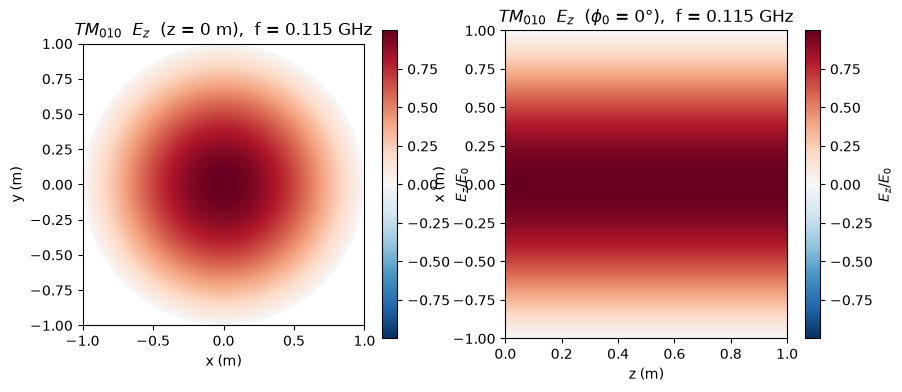

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_Ez_pillbox(0,1,0, ax=axes[0])
plot_Ez_pillbox(0,1,0,plane="rz", ax=axes[1])

(<Axes: title={'center': '$TM_{110}$  $E_z$  ($\\phi_0$ = 0°),  f = 0.183 GHz'}, xlabel='z (m)', ylabel='x (m)'>,
 np.float64(182823917.32568905))

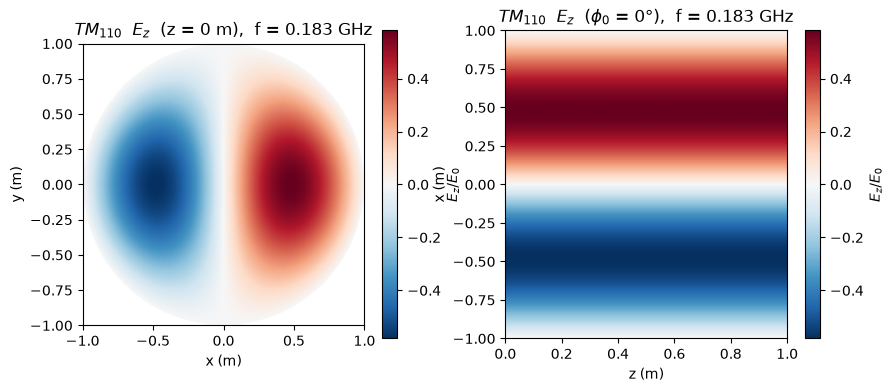

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_Ez_pillbox(1,1,0, ax=axes[0])
plot_Ez_pillbox(1,1,0,plane="rz", ax=axes[1])

(<Axes: title={'center': '$TM_{011}$  $E_z$  ($\\phi_0$ = 0°),  f = 0.189 GHz'}, xlabel='z (m)', ylabel='x (m)'>,
 np.float64(188771627.0058464))

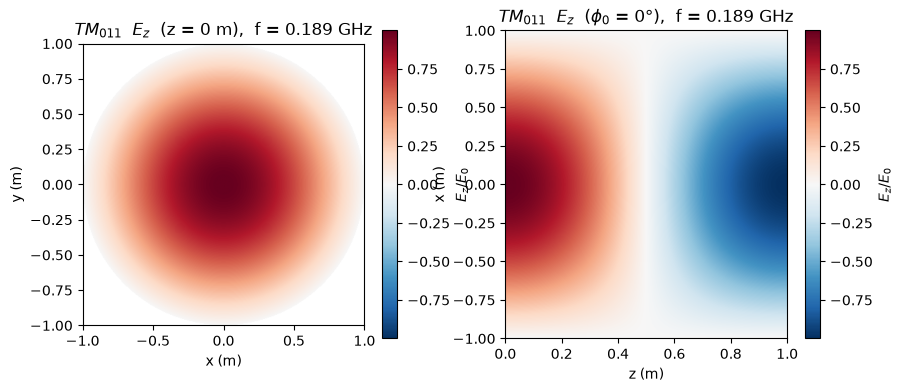

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_Ez_pillbox(0,1,1, ax=axes[0])
plot_Ez_pillbox(0,1,1,plane="rz", ax=axes[1])